# 15 分钟生活圈健康体检 · 实验总集

> 基于百度地图开放平台(直连 API)+ OSMnx 双仪器的等时圈方法学实验。
> 二十社区(直辖/省会/地级/县级)、全台账可审计(~2 万对调用)、本 notebook **全部离线重放,零 API**。
> 数据:`experiments/results/`;台账:`experiments/logs/calls.db`;报告:`docs/01-13`。

## 0.1 最终算法(一页纸)

```text
等时圈 = 射线二分(8 向起步×tol50) + 弦规则加密(实测超时证据/θ≥30°,收敛 k=16~87)
      + 多 15min 点(复通带 pocket={r, gap:[g0,g1], outer})
      + 多边形判定(边界) + Delaunay(时间场,50m 分辨率重建)
复杂地形 = 地形感知加向 + mid/ρ 双探针 + 弦差再平衡(Δ>150m 必插)
降级兜底 = 直线 × 城市绕行系数 ρ / 4.2 km/h
验证 = OSM 双仪器交叉(分层采信;落址前百度破平) + 弦/mid 探针作收敛判据(不是 F1)
成本 = 自适应8起步 104-212 对/城(低于 16 起步);含真值与验证 317-1034 对/城
```

In [1]:
import sys, os, json, math
import pandas as pd
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), '..', '..')))
from experiments.paths import RESULTS, LOGS

FILES = {'A': ('e4_sampling', 'e4.json', 'm4_radii'), 'B': ('e4_sampling', 'e4b.json', 'radii_final')}
SLUGS = ['A','B','shanghai','guangzhou','chengdu','harbin','xian','chongqing',
         'changsha','wuhan','luoyang','kunshan','guilin','zunyi','yiwu',
         'nanchang','huilongguan','zhangjiang','zhujiangxincheng','yulin_cd']
def load(slug):
    sub, fn, rk = FILES.get(slug, ('e10_boundary', f'e10x_{slug}.json', 'radii'))
    d = json.load(open(os.path.join(RESULTS, sub, fn), encoding='utf-8'))
    return d, {float(k): v for k, v in d[rk].items()}

rows = []
for s in SLUGS:
    d, r = load(s)
    m = d.get('metrics', {})
    fu = m.get('fusion', {})
    aniso = d.get('anisotropy') or round(max(r.values()) / max(1e-9, min(r.values())), 2)
    rows.append({
        '城市': d.get('city') or d.get('community') or s,
        '类型': d.get('type') or ('胡同步行街' if s == 'A' else '老居住区' if s == 'B' else ''),
        '射线': len(r), '各向异性': aniso,
        '半径m': f"{d['radius_range'][0]}-{d['radius_range'][1]}" if d.get('radius_range')
                else f"{min(r.values()):.0f}-{max(r.values()):.0f}",
        'IoU多边形': m.get('iou'), 'IoU融合+复通带': fu.get('R2并+口袋'),
        '带外误差': m.get('out_band_errors'), '复通带': len(d.get('pockets') or []),
        '总对数': d.get('pairs_used')})
df = pd.DataFrame(rows)
df

,城市,类型,射线,各向异性,半径m,IoU多边形,IoU融合+复通带,带外误差,复通带,总对数
0,A,胡同步行街,16,1.47,664-973,0.896,0.930,1,0,2331.0
1,B,老居住区,32,2.26,467-1058,0.960,1.000,0,0,566.0
2,上海·陆家嘴,CBD超级街区+黄浦江,29,1.89,495-936,0.935,1.000,0,0,442.0
3,广州·上下九,老城窄巷+河涌,44,1.43,702-1002,1.000,1.000,0,0,459.0
4,成都·九眼桥,规则路网+府河,21,1.27,786-1002,0.906,0.922,1,0,317.0
5,哈尔滨·道外,北方老城+江/铁路,95,2.25,561-1264,0.854,0.927,1,2,480.0
6,西安·钟楼,明城墙环障,42,1.49,580-861,0.894,0.896,1,0,833.0
7,重庆·解放碑,立体过街/山城,95,3.14,289-908,0.906,0.938,1,1,894.0
8,长沙·五一广场,商圈规则+湘江,119,2.13,430-917,0.896,0.938,1,1,1034.0
9,武汉·江汉路,老城+长江,45,1.91,636-1217,0.905,0.937,2,0,932.0


## 0.2 一图流结论

- **难度主变量是地形/水系,不是城市规模**:小城桂林(漓江)各向异性 4.62 二十社区之最,超过山城重庆 3.14
- **8 向起步+弦规则加密**十城全面省于 16 起步且收敛同形;k 值即城市难度(昆山 23 → 长沙 84)
- **F1/IoU 会说谎,弦/mid 探针才是收敛判据**(哈尔滨 8向 F1 反超成品;四城违规清零 IoU 一字不变)
- **OSM 只能初筛**:教育选址 OSM 100% → 百度实测 8.7%,换址后 87%——落址前必须百度破平

## 1. 仪器标定(E0-E2 + E3 并发)

回答:AK/签名/坐标系/批量测距可信吗?并发上限在哪?

- 五服务体检 + SN 签名踩坑(逗号安全表)+ IP 白名单切换 → `docs/01`
- 坐标系:BD-09(百度)/GCJ-02/WGS-84(OSM、H3)三系转换,`core/coord.py`(迭代逆推)
- 批量 routematrix:50 对/请求,~50× 加速;二分收敛阈值 15m 内时长 σ=0

In [2]:
e3 = json.load(open(os.path.join(RESULTS, 'e0_instrument', 'e3_concurrency.json'), encoding='utf-8'))
pd.DataFrame([{'档位QPS': k, **{kk: vv for kk, vv in v.items() if kk != 'statuses'},
               '状态分布': v['statuses']} for k, v in e3['tiers'].items()])

,档位QPS,n,ok,latency_p50_ms,latency_p95_ms,mean_ms,状态分布
0,2,40,40,1664,1757,1655,{'0': 40}
1,4,40,40,1661,1748,1651,{'0': 40}
2,8,40,40,1661,2029,1684,{'0': 40}
3,16,40,40,1715,2173,1751,{'0': 40}


In [3]:
import sqlite3
con = sqlite3.connect(os.path.join(LOGS, 'calls.db'))
tot = pd.read_sql("SELECT COUNT(*) AS 次数, SUM(n_pairs) AS 对数 FROM calls", con)
by_eid = pd.read_sql("""SELECT experiment_id AS EID, COUNT(*) AS 次数, SUM(n_pairs) AS 对数,
                       MIN(ts) AS 起, MAX(ts) AS 止 FROM calls GROUP BY 1 ORDER BY 对数 DESC""", con)
display(tot); by_eid.head(25)

,次数,对数
0,5907,22032


,EID,次数,对数,起,止
0,E4,53,2331,2026-08-25T13:44:41,2026-08-25T13:49:59
1,E50M,47,2168,2026-08-26T09:35:02,2026-08-31T09:25:03
2,E4N2,156,1034,2026-08-26T10:25:57,2026-08-26T10:33:52
3,E4N3,139,932,2026-08-26T10:33:56,2026-08-26T10:40:47
4,E4N1,133,894,2026-08-26T10:19:37,2026-08-26T10:25:54
5,E4N0,111,833,2026-08-26T10:14:14,2026-08-26T10:19:34
6,MCLPV,20,778,2026-08-31T09:53:21,2026-08-31T09:56:25
7,DEMO_NC,663,755,2026-08-31T14:01:30,2026-08-31T14:55:24
8,E4B,111,566,2026-08-25T14:34:09,2026-08-25T14:39:47
9,S52,105,543,2026-08-31T10:49:13,2026-08-31T11:19:32


## 2. 采样策略对比(E4,杀手表)

七方法同场竞技(社区 A):均匀网格 50-250m / 射线 16-32 / 自适应扇形 / H3 AMR。
三轮口径修正(IDW→多边形→Delaunay)后的结论:**射线+多边形判定 ≈ 全网格,而调用数少 4 倍**。

In [4]:
ea = json.load(open(os.path.join(RESULTS, 'e4_sampling', 'e4_analysis.json'), encoding='utf-8'))
pd.json_normalize(ea)

,experiment,center,methods,ref_boundaries_m.0,ref_boundaries_m.45,ref_boundaries_m.90,ref_boundaries_m.135,ref_boundaries_m.180,ref_boundaries_m.225,ref_boundaries_m.270,ref_boundaries_m.315
0,E4-analysis,"[39.92256304162586, 116.41759225843734]","[{'method': 'M1 网格200m', 'pairs': 121, 'reques...",935.0,665.0,825.0,755.0,975.0,685.0,775.0,755.0


## 3. 插值选型(E6)与绕行系数(E5,二十社区 ρ 表)

- Delaunay 线性插值胜出(IDW 高次在凹口震荡;多边形分类快但无场)——即地图黑线"50m 网格·重建"
- ρ = 实际步行时长 / 直线时长@4.2km/h,降级兜底用;二十社区中位 1.29-1.98(桂林 0.91 为端点吸附效应,仅参考)

In [5]:
rho_rows = []
for s in SLUGS:
    d, _ = load(s)
    rho = d.get('rho') or {}
    rho_rows.append({'城市': d.get('city', s), 'ρ中位': rho.get('median'),
                     'τ(P75)': rho.get('tau_p75'),
                     '热弦数': len(rho.get('hot_chords') or [])})
pd.DataFrame(rho_rows)

,城市,ρ中位,τ(P75),热弦数
0,A,NaN,NaN,0
1,B,NaN,NaN,0
2,上海·陆家嘴,1.47,1.90,5
3,广州·上下九,1.38,2.02,5
4,成都·九眼桥,1.67,2.16,5
5,哈尔滨·道外,1.44,2.25,5
6,西安·钟楼,1.78,2.30,5
7,重庆·解放碑,1.87,2.74,5
8,长沙·五一广场,1.29,2.04,5
9,武汉·江汉路,1.65,2.50,5


## 4. 极端边界与三防线(E10)+ 复通带

墙/河/铁路造成的幻影边界如何防:
1. **mid 探针**(弦中点 0.97r)抓凹口;2. **ρ 探针**抓跨障弦;3. **孤岛抽检** K 点终审。
收敛判据从"3 轮"改为**违规清零或预算耗尽**(四城续跑清零:西安 28/重庆 41/长沙 84/武汉 54 向)。
**复通带**:一根射线上 15min 线多次穿越(垂直凹腔),表示为 pocket={r, gap, outer},全二十社区共 6 条(哈×2/渝/沙/桂/遵)。

In [6]:
pk_rows = []
for s in SLUGS:
    d, r = load(s)
    for pk in (d.get('pockets') or []):
        if isinstance(pk.get('gap'), list):
            pk_rows.append({'城市': d.get('city', s), '方位°': pk['bearing'],
                            '主边界r': pk.get('r'), '隔离带m': f"{pk['gap'][0]}-{pk['gap'][1]}",
                            '复通至': pk.get('outer'), '半宽°': pk.get('wedge_deg')})
pd.DataFrame(pk_rows)

,城市,方位°,主边界r,隔离带m,复通至,半宽°
0,哈尔滨·道外,33.7,561,648-731,771,8.4
1,哈尔滨·道外,45.0,608,654-716,861,8.4
2,重庆·解放碑,153.4,298,310-477,508,8.4
3,长沙·五一广场,157.5,467,478-498,708,8.4
4,桂林·东西巷,163.1,416,428-571,587,8.4
5,遵义·老城,135.0,598,606-739,779,8.4


## 5. 二十社区地图(v6 图层)

图例(方法本名+实际对数):自适应扇形·16/8起步、16/8 向均匀基线、50m 网格·重建(黑,
Delaunay+弦约束)、粗网格线、H3 AMR(仅A)、OSMnx 参照、射线(基线/加密分色)、
**玫红 X=每向全部 15min 穿越点**、**青绿楔=复通带**。小城五城按指示无 OSM 底图。

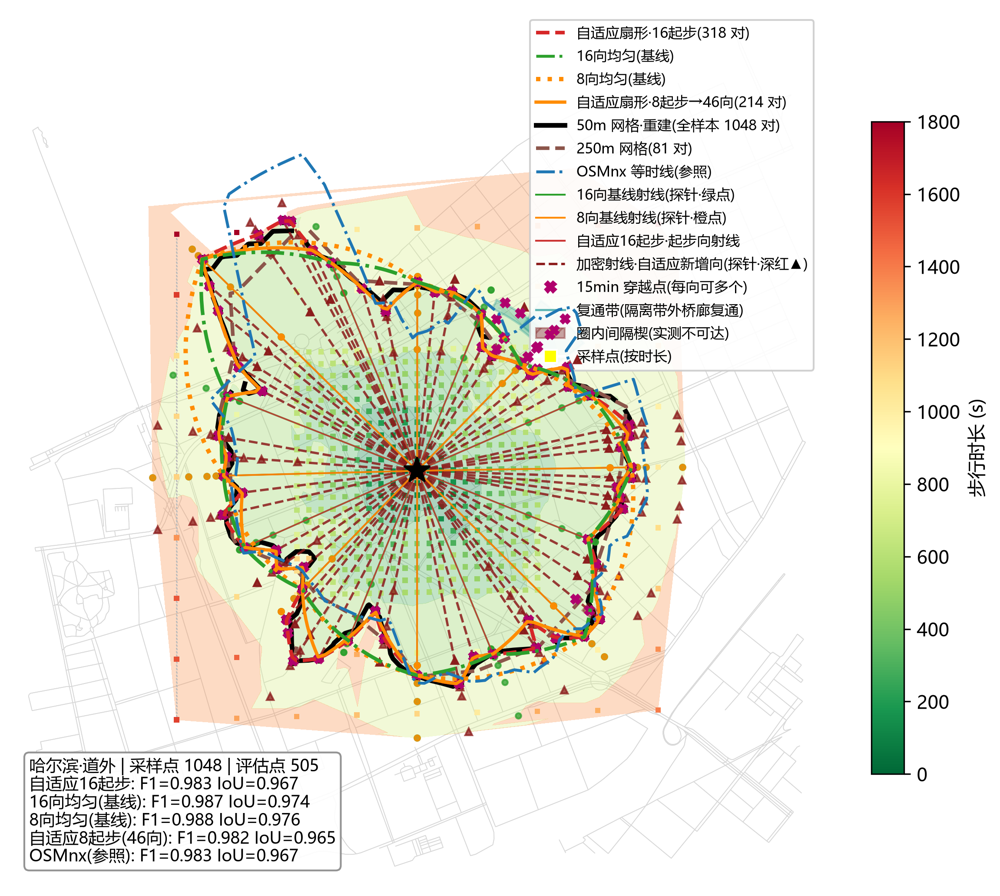

In [7]:
from IPython.display import Image, display
from PIL import Image as PILImage
os.makedirs('assets', exist_ok=True)
def show(slug, w=1000):
    src = os.path.join(RESULTS, 'maps', f'{slug}.png')
    dst = os.path.join('assets', f'{slug}_s.png')
    im = PILImage.open(src); im.thumbnail((w, w)); im.save(dst)
    display(Image(dst))
show('harbin')   # 最难:k=42,含 2 条复通带

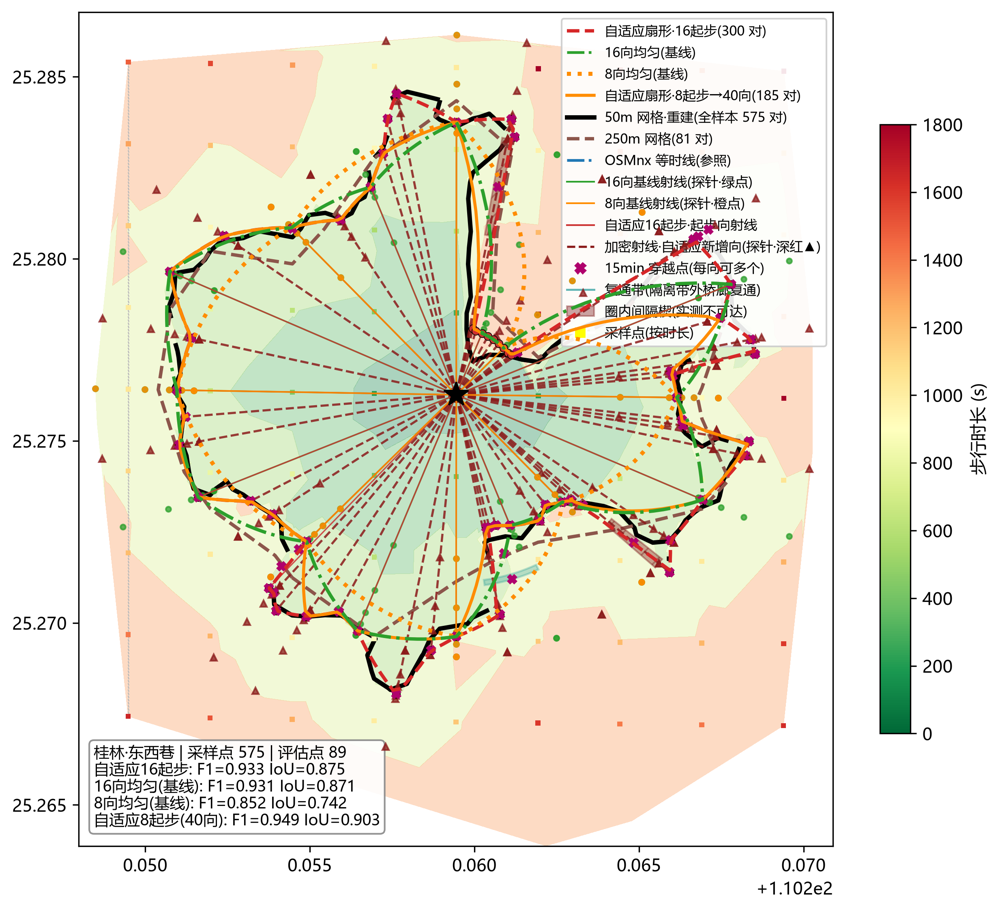

In [8]:
show('guilin')   # 各向异性之最 4.62(漓江),1 条复通带

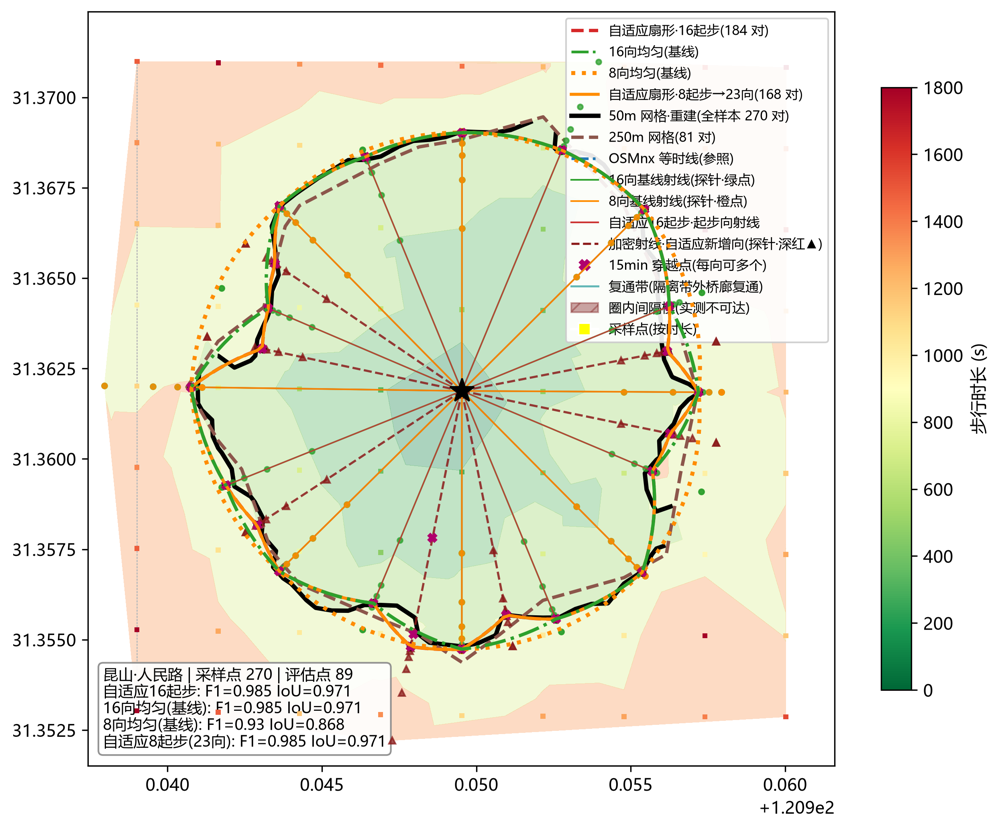

In [9]:
show('kunshan')   # 最易:平原县级市,k=23,IoU 0.967

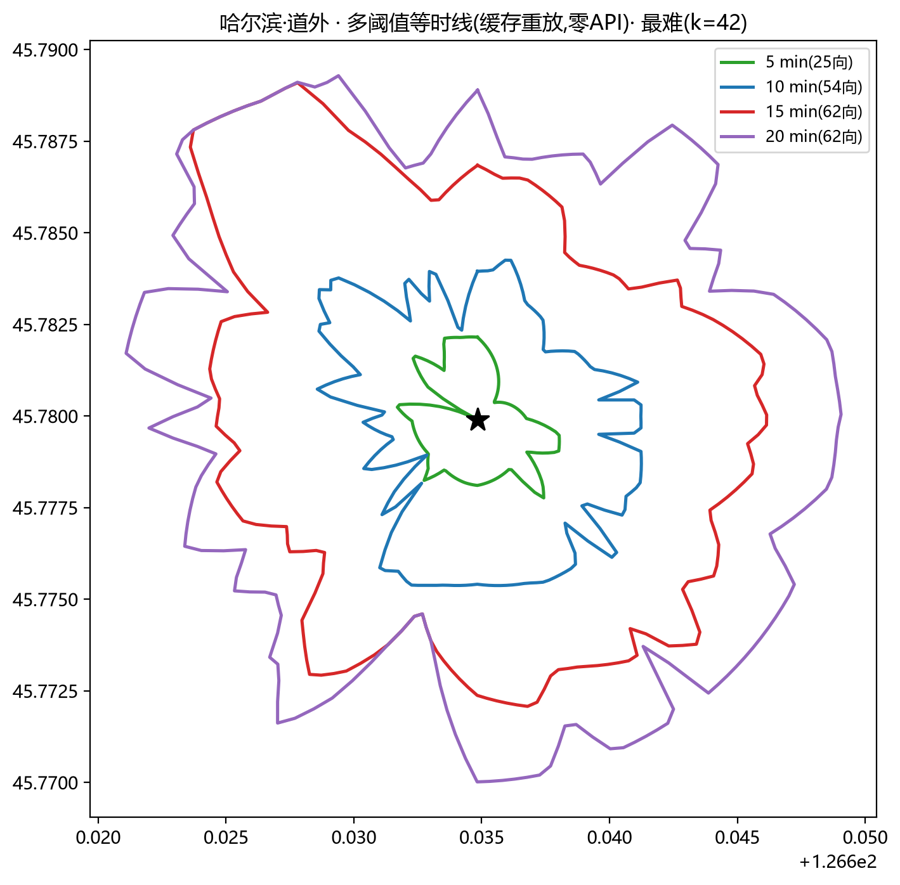

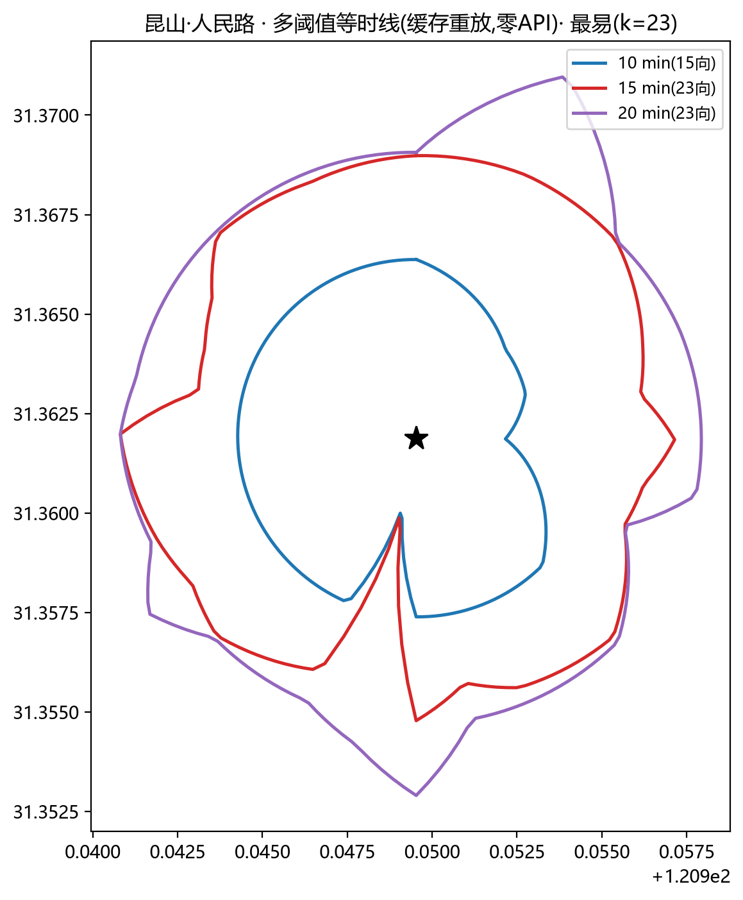

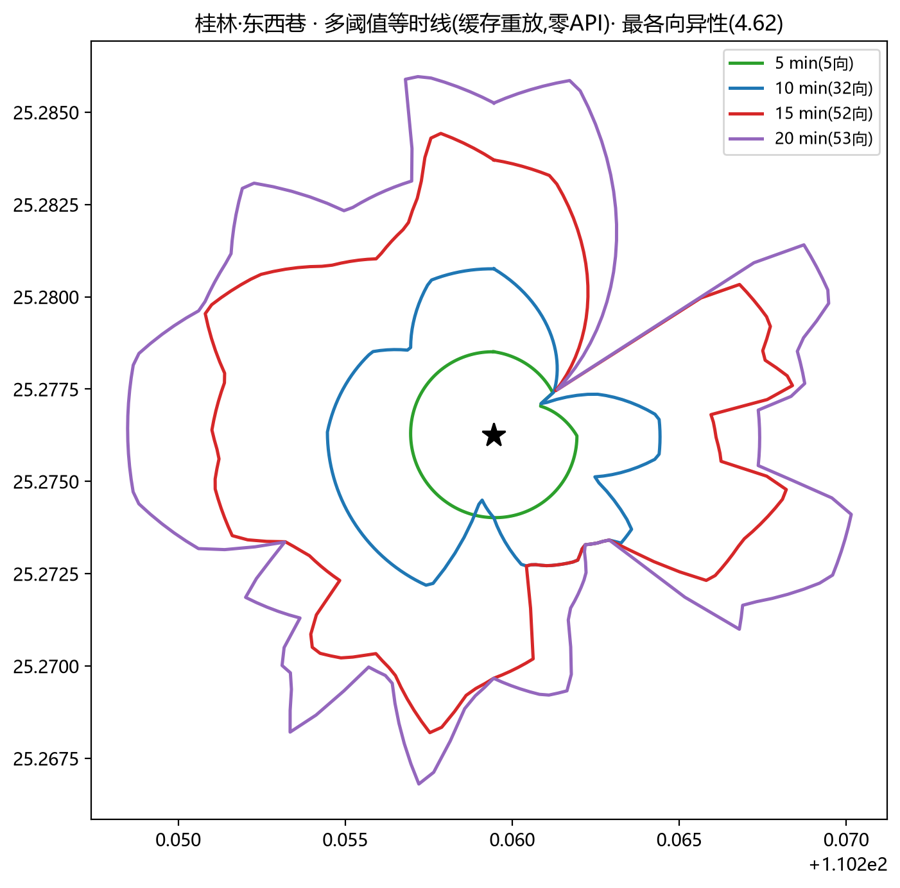

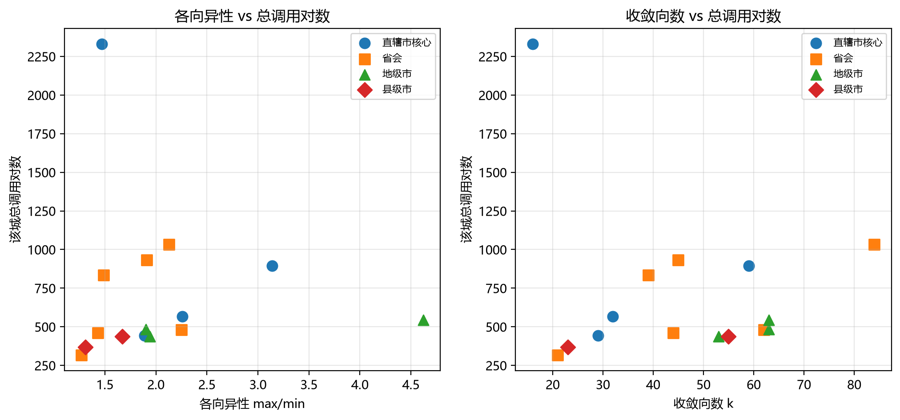

In [10]:
# 多阈值等时线(5/10/15/20min,缓存重放零 API)与规模-难度回归
for f in ['multi_threshold_harbin.png', 'multi_threshold_kunshan.png',
          'multi_threshold_guilin.png', 'size_difficulty.png']:
    src = os.path.join(RESULTS, 'maps', f); dst = os.path.join('assets', f)
    im = PILImage.open(src); im.thumbnail((900, 900)); im.save(dst)
    display(Image(dst))

## 6. 边界优化三役与事故复盘(docs/13)

| 役 | 动作 | 二十社区平均 IoU |
|---|---|---|
| 基线 | 射线多边形 R0 | 0.904 |
| 一 | 融合分类器(多边形∪重建场,留出选优) | 0.933 |
| 二 | ρ 热弦插向 + 弦差再平衡(义乌针→有宽度凹槽) | 0.933 |
| 三 | 复通带并入(R2并+口袋) | **0.933** |

义乌"针"复盘:95.6°=486m vs 邻 842/805m——三射线距离阶梯证实为**真实窄槽**(铁路),
算法错在单射线渲染成针;弦差再平衡(Δ>150m 必插)修复。

**两次实现事故(教训:截断≠失败,必须显式暴露)**:
1. REBAL v1 预算按全局 EID 计数 → 首城耗尽后 14 城 bisect 零探针仍写盘(135 条 800m 假半径,已清);
2. BAND v1 二分方向写反(已重写)。v2 均加"零消耗批次整批丢弃"守卫。

In [11]:
rules = ['R0多边形', 'R1场', 'R2并', 'R3交', 'R4带内多边形+带外场', 'R2并+口袋']
agg = {r: [] for r in rules}
for s in SLUGS:
    d, _ = load(s)
    fu = d.get('metrics', {}).get('fusion', {})
    for r in rules:
        if fu.get(r) is not None:
            agg[r].append(fu[r])
pd.DataFrame([{'规则': r, '二十社区平均IoU': round(sum(v)/len(v), 3), '城数': len(v)}
              for r, v in agg.items()]).sort_values('二十社区平均IoU', ascending=False)

,规则,二十社区平均IoU,城数
1,R1场,0.943,20
2,R2并,0.940,20
5,R2并+口袋,0.940,20
3,R3交,0.911,20
0,R0多边形,0.908,20
4,R4带内多边形+带外场,0.907,20


## 7. OSMnx 双仪器交叉验证

OSM 作"参照真值"必须分层采信:一致性 r 从 0.12(陆家嘴,OSM 失真反例)到 0.93;
哈尔滨路网 943 节点经多端点重下复核(845)确认为棚改区真实肌理。详见 `docs/05/06`。

In [12]:
oc = json.load(open(os.path.join(RESULTS, 'osmnx', 'osmnx_cities.json'), encoding='utf-8'))
pd.json_normalize(oc).head(10) if isinstance(oc, list) else pd.json_normalize(oc)

,北京B·东花市.calibration.n,北京B·东花市.calibration.mae_s,北京B·东花市.calibration.bias_s,北京B·东花市.calibration.r,北京B·东花市.calibration.cls_agree,北京B·东花市.absolute.n,北京B·东花市.absolute.f1,北京B·东花市.absolute.iou,北京B·东花市.absolute.bnd_mean_m,北京B·东花市.absolute.bnd_max_m,...,哈尔滨·道外.barrier_prior.n_viol,哈尔滨·道外.barrier_prior.n_hot,哈尔滨·道外.barrier_prior.hit_viol,哈尔滨·道外.barrier_prior.hit_hot,哈尔滨·道外.config_grid,哈尔滨·道外.config_best.rays,哈尔滨·道外.config_best.tol_m,哈尔滨·道外.config_best.probes,哈尔滨·道外.config_best.f1,哈尔滨·道外.config_best.iou
0,558,189,119,0.809,0.783,225,0.832,0.712,110,250,...,15,5,0,0,"[{'rays': 8, 'tol_m': 15, 'probes': 64, 'f1': ...",24,15,192,0.972,0.946


## 8. 体检 → 处方 → 一键管线(E7/E9/E10/E8)

哈尔滨·道外全链路(养老词表补全后 v2):
- **体检 94.1/100**(养老 0→6 家,单关键词→taxonomy 召回实证)
- **处方**(OSM 初筛+百度破平):养老 3 站百度口径 **98.5%**;教育换址 **87%**(旧址 OSM 100%→百度 8.7%)
- **E8 管线** `python experiments/pipeline.py`:地址→等时圈→体检→评分→选址→报告,**二跑零调用断言通过**

In [13]:
poi = json.load(open(os.path.join(RESULTS, 'poi', 'poi_harbin.json'), encoding='utf-8'))
W = {'医疗': .25, '教育': .20, '购物': .20, '药店': .15, '养老': .20}
n_in = poi['grid_blind']['n_inside_cells']
rows = []
for c, w in W.items():
    blind = poi['grid_blind']['by_cat'][c]['blind_gt15']
    rows.append({'类目': c, '权重': w, '格网覆盖率': f"{(n_in-blind)/n_in*100:.1f}%",
                 '15min内/总数': f"{poi['categories'][c]['n_in15']}/{poi['categories'][c]['n_total']}"})
dfp = pd.DataFrame(rows); display(dfp)
score = sum(w * (n_in - poi['grid_blind']['by_cat'][c]['blind_gt15']) / n_in * 100
            for c, w in W.items())
print(f"综合评分 {score:.1f} / 100(与 docs/09 手算一致)")

,类目,权重,格网覆盖率,15min内/总数
0,医疗,0.25,100.0%,37/114
1,教育,0.20,97.2%,1/14
2,购物,0.20,100.0%,7/50
3,药店,0.15,100.0%,23/69
4,养老,0.20,73.5%,1/6


综合评分 94.1 / 100(与 docs/09 手算一致)


In [14]:
bk = json.load(open(os.path.join(RESULTS, 'osmnx', 'mclp_baidu_check.json'), encoding='utf-8'))
rows = []
for pname, blk in bk['results'].items():
    for site in blk['sites']:
        rows.append({'问题': pname, 'k': site['k'], '选址': tuple(site['site']),
                     'OSM%': site['osm_cum_pct'], '百度%': site['baidu_cum_pct']})
pd.DataFrame(rows)

,问题,k,选址,OSM%,百度%
0,养老(全盲),1,"(45.787629, 126.647361)",95.5,95.0
1,养老(全盲),2,"(45.788527, 126.646073)",96.5,96.5
2,养老(全盲),3,"(45.780442, 126.647361)",100.0,98.5
3,教育(轻度盲区),1,"(45.784036, 126.642209)",100.0,8.7


## 9. 已排期实验(docs/11 追加设计)与遗留

- **E11 邻近点缓存(跨源复用)**:离线用异源数据标定 ΔT(d) 包络 → 在线 A/B;预期省 20-40%
- **E12 起步向数路由**:免费信号(OSM aniso/河网/规模)+ 二十社区 k 标签 → 8/16 决策规则
- REBAL 未做的 7 城(上海/武汉/广州/B/昆山/A/成都,预算触顶,~250 对)
- 第二社区体检泛化(~30 对);盲区 20 格人工街景核对(人工)
- 配额:2026-08-31 单日 4770/5000 对,全台账 `calls.db` 可审计